# 🚗 **Welcome to the <font color='crimson'>** **Explorer Transportation Data Science Project! 🚗**</font>
 Hosted by the [Northeast Big Data Innovation Hub](https://nebigdatahub.org/about) & [National Student Data Corps](https://nebigdatahub.org/nsdc), in collaboration with the [U.S. Department of Transportation Federal Highway Administration](https://highways.dot.gov/).


---



## <font color='crimson'>**Milestone #1 - Data Preparation**</font>
GOAL: The main goal of this milestone is to set up your environment, install the required packages, learn how to access data and do some basic exploratory data analysis.
  

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# TODO: Read the data using pandas read_csv function
data = pd.read_csv("/content/drive/MyDrive/Motor_Vehicle_Collisions_-_Crashes_20260611.csv")

/tmp/ipykernel_8959/3686063682.py:2: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("/content/drive/MyDrive/Motor_Vehicle_Collisions_-_Crashes_20260611.csv")


In [5]:
# TODO: Print the first 5 rows of the data using head function of pandas
print(data.head())

   CRASH DATE CRASH TIME   BOROUGH ZIP CODE  LATITUDE  LONGITUDE  \
0  09/11/2021       2:39       NaN      NaN       NaN        NaN   
1  03/26/2022      11:45       NaN      NaN       NaN        NaN   
2  11/01/2023       1:29  BROOKLYN  11230.0  40.62179 -73.970024   
3  06/29/2022       6:55       NaN      NaN       NaN        NaN   
4  09/21/2022      13:21       NaN      NaN       NaN        NaN   

                     LOCATION           ON STREET NAME CROSS STREET NAME  \
0                         NaN    WHITESTONE EXPRESSWAY         20 AVENUE   
1                         NaN  QUEENSBORO BRIDGE UPPER               NaN   
2      (40.62179, -73.970024)            OCEAN PARKWAY          AVENUE K   
3                         NaN       THROGS NECK BRIDGE               NaN   
4                         NaN          BROOKLYN BRIDGE               NaN   

  OFF STREET NAME  ...  CONTRIBUTING FACTOR VEHICLE 2  \
0             NaN  ...                    Unspecified   
1             NaN  .

In [6]:
# TODO: Describe the data using the describe function of pandas
desc_stats = data.describe()
desc_stats

,LATITUDE,LONGITUDE,NUMBER OF PERSONS INJURED,NUMBER OF PERSONS KILLED,NUMBER OF PEDESTRIANS INJURED,NUMBER OF PEDESTRIANS KILLED,NUMBER OF CYCLIST INJURED,NUMBER OF CYCLIST KILLED,NUMBER OF MOTORIST INJURED,NUMBER OF MOTORIST KILLED,COLLISION_ID
count,2.027765e+06,2.027765e+06,2.268549e+06,2.260274e+06,2.268567e+06,2.268567e+06,2.268567e+06,2.268567e+06,2.268567e+06,2.268567e+06,2.268567e+06
mean,4.057175e+01,-7.365026e+01,3.332249e-01,1.600248e-03,6.071939e-02,7.956565e-04,2.966057e-02,1.295972e-04,2.380119e-01,6.457821e-04,3.300014e+06
std,2.485497e+00,4.605012e+00,7.186103e-01,4.221063e-02,2.521426e-01,2.883002e-02,1.719846e-01,1.142200e-02,6.798280e-01,2.775886e-02,1.511505e+06
min,0.000000e+00,-2.013600e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.200000e+01
25%,4.066724e+01,-7.397446e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.203262e+06
50%,4.072016e+01,-7.392653e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.770602e+06
75%,4.076963e+01,-7.386637e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.337940e+06
max,4.334444e+01,0.000000e+00,4.300000e+01,8.000000e+00,2.700000e+01,6.000000e+00,4.000000e+00,2.000000e+00,4.300000e+01,5.000000e+00,4.905446e+06




---



##<font color='crimson'> **Milestone #2 - Data Ethics, Pre-Processing, and Exploration** </font>
GOAL: The main goal of this milestone is to assess the dataset, find missing values, and decide what to do with those missing data points.

**Step 1:**
Before we begin assessing our data for missing values, it is important that we understand the ethical implications surrounding data processing. To best prepare yourself for this module, review one or more of the following resources:
- [Data Science Ethics Flashcard Video Series](https://youtube.com/playlist?list=PLNs9ZO9jGtUB7XTjXy-ttoo2QSLld9SrV&feature=shared)
- [What Do I Need to Understand about Data Ethics?](https://www.youtube.com/watch?v=Efy8htCDueE)
-[Introduction to Data Cleaning](https://www.youtube.com/watch?v=t8WkoGLkdTk)

**TO DO:** Based on the resources above and outside knowledge, what are some potential bias issues related to the availability of data from well-resourced communities as compared to under-resourced communities? How might bias show up in our dataset?

> Answer here:
The availability of data varies. Communities with greater resources typically have more sensors, more police and agency personnel, and more residents who report issues, so more of what occurs there is captured on camera. The data may make under-resourced places appear safer or less impacted than they actually are since they frequently receive less coverage and reporting. A similar argument is made in the data ethics video which is that bias can enter at any step in the data cycle, including collecting. A school allergy survey completed at the lunch checkout serves as an example. Students who pack their own lunches are missed, and many of them may do so due to allergies. Who appears in the data depends on how it is gathered. One way bias could show up in our dataset is that a collision only appears if someone reports it and an agency records it, so minor crashes in under-resourced areas may be missing.



**Step 2:**
Check the dataset for missing values.


In [7]:
#TODO: Leverage the isnull() and sum() functions to find the number of missing values in each column
missing_values = data.isnull().sum()

#TODO: Turn the missing value counts into percentages
missing_values_percentage = (missing_values / len(data)) * 100

#TODO: Return counts and percentages of missing values in each column
missing_data = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_values_percentage})
missing_data.sort_values(by='Percentage (%)', ascending=False)

,Missing Values,Percentage (%)
VEHICLE TYPE CODE 5,2258581,99.559810
CONTRIBUTING FACTOR VEHICLE 5,2258255,99.545440
VEHICLE TYPE CODE 4,2232332,98.402736
CONTRIBUTING FACTOR VEHICLE 4,2230944,98.341552
VEHICLE TYPE CODE 3,2110785,93.044860
CONTRIBUTING FACTOR VEHICLE 3,2104236,92.756176
OFF STREET NAME,1861977,82.077232
CROSS STREET NAME,869940,38.347556
ZIP CODE,691519,30.482635
BOROUGH,691233,30.470028


Here's an overview of the missing values in the dataset:

Columns like VEHICLE TYPE CODE 5, CONTRIBUTING FACTOR VEHICLE 5, VEHICLE TYPE CODE 4, and so on have a high percentage of missing values. This is expected since not all crashes involve multiple vehicles or factors.

OFF STREET NAME and CROSS STREET NAME have significant missing values. This could be due to crashes occurring in locations where these details aren't applicable or weren't recorded.

ZIP CODE, BOROUGH, and ON STREET NAME also have missing values. This might be due to incomplete data entry or crashes occurring in areas where these specifics aren't easily determinable.

LOCATION, LATITUDE, and LONGITUDE have the same count of missing values, indicating that when one is missing, the others are likely missing as well.

**Step 3:** Create a bar chart to display the top 10 contributing factors (e.g. backing up unsafely, unsafe lane changing, etc.) to crashes within the dataset.

/tmp/ipykernel_8959/242484946.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_factors.index, y=top_factors.values, palette="magma")


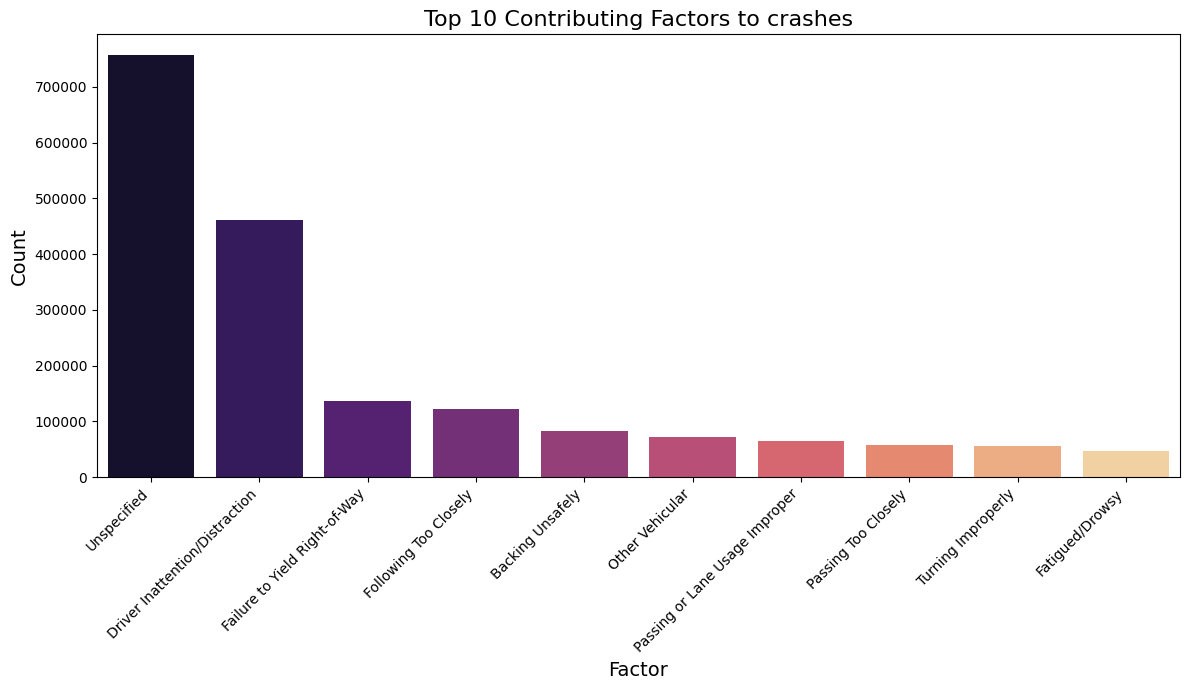

In [8]:
#TODO: Plot a Bar Chart

top_factors = data['CONTRIBUTING FACTOR VEHICLE 1'].value_counts().head(10)


plt.figure(figsize=(12, 7))
# TODO: Plotting the top contributing factors, fill in x as the index field of the variable 'top_factors'
sns.barplot(x=top_factors.index, y=top_factors.values, palette="magma")
plt.title('Top 10 Contributing Factors to crashes', fontsize=16)
plt.xlabel('Factor', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**TO DO:** Besides for "Unspecified," what are the top 3 contributing factors that cause the most crashes?

> *  Driver Inattention/Distraction
> *  Failure to Yield Right-Of-Way
> *  Following Too Closely

**TO DO:** What recommendations would you make to new and current drivers after assessing the above data?


*   Make sure to keep your eyes on the road and put down any devices that may distract you.
*   Review the drivers handbook for rules on when to yield right of way


*   Make sure that theres enough space between you and the driver in front of you at all times. You should be able to see the tires of the car in front of you.









**Step 4:** Now, let's create another bar chart to determine which vehicle types were involved in the most crashes.

/tmp/ipykernel_8959/1703702012.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_vehicle_types.index, y=top_vehicle_types.values, palette="cividis")


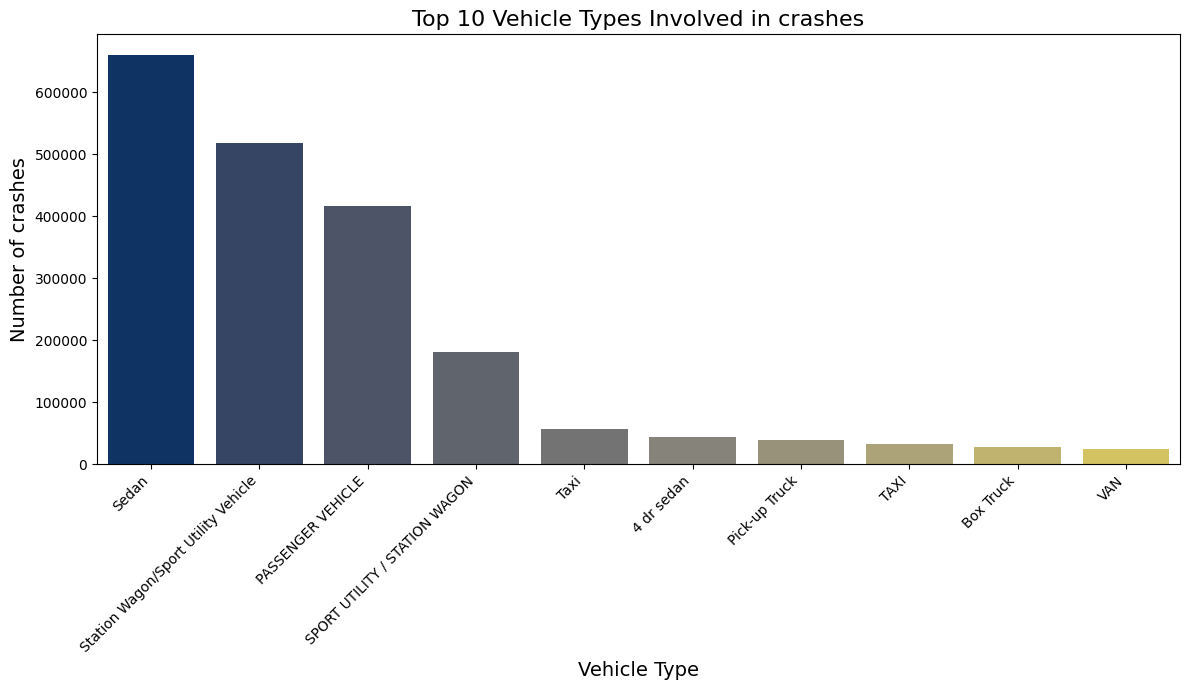

In [9]:
# Determine the top vehicle types involved in crashes
top_vehicle_types = data['VEHICLE TYPE CODE 1'].value_counts().head(10)

# Plotting the top vehicle types
plt.figure(figsize=(12, 7))
sns.barplot(x=top_vehicle_types.index, y=top_vehicle_types.values, palette="cividis")
plt.title('Top 10 Vehicle Types Involved in crashes', fontsize=16)
plt.xlabel('Vehicle Type', fontsize=14)
plt.ylabel('Number of crashes', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**TO DO:** What are the top 3 vehicles that were most involved in crashes?


> *   Station Wagon/Sport Untiliy Vehicles
> *   Passenger Vehicles
> *   Sedan







**TO DO:** Why do you think that "Sedan[s]," "Station Wagon[s]," and "Passenger Vehicle[s]" are involved in a larger number of crashes, injuries, and deaths when compared to the rest of the vehicles? (Think outside the box!)


> *  These are the most common vehicles on NYC roads, so they appear in more crashes simply because there are more of them.






**TO DO:** Review the x-axis of the bar chart you created above. </br>
1) What do you notice? </br>
2) What would you recommend we do to improve the bar chart, based on the x-axis (horizontal axis) and why? </br>
3) What recommendation would you make to those who are collecting and/or inputting data into this dataset?


> *  1) The same vehicle type appears under several spellings, so its crashes are split across bars. “Taxi” and “TAXI” are separate bars, as are “Station Wagon/Sport Utility Vehicle” and “SPORT UTILITY / STATION WAGON,” and “Sedan” and “4 dr sedan."
> *  2) Standardize the labels before counting. Convert everything to one case, trim spaces, and map variants to one name, for example “4 dr sedan” to “Sedan.” Then recount.
> *  3) Replace free-text entry with a fixed dropdown list of vehicle types, so everyone picks from the same options.






**Step 5:**  A DataFrame is a two-dimensional and potentially heterogeneous tabular data structure with labeled axes (rows and columns). DataFrames allow for storing, manipulating, and retrieving data in a structured form, serving as the primary data structure for a multitude of data processing tasks. It is used with Python libraries like pandas.

Let's graph the *types* of crashes within this dataset and their frequencies. Begin by aggregating your data, convert to [DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) for simple plotting, and plot.



/tmp/ipykernel_8959/1778535479.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='crash Type', data=crash_types_df, palette="mako")


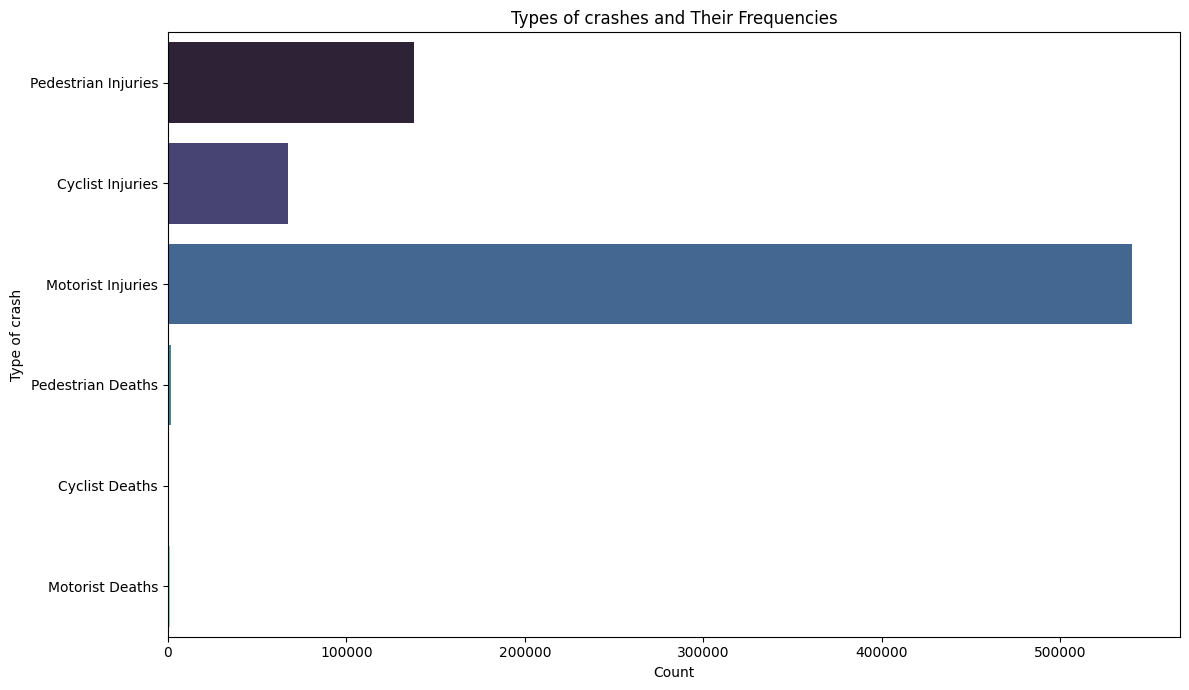

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregating data - Complete for Cyclist and Motorist
types_of_crashes = {
    'Pedestrian Injuries': data['NUMBER OF PEDESTRIANS INJURED'].sum(),
    'Cyclist Injuries': data['NUMBER OF CYCLIST INJURED'].sum(),
    'Motorist Injuries': data['NUMBER OF MOTORIST INJURED'].sum(),
    'Pedestrian Deaths': data['NUMBER OF PEDESTRIANS KILLED'].sum(),
    'Cyclist Deaths': data['NUMBER OF CYCLIST KILLED'].sum(),
    'Motorist Deaths': data['NUMBER OF MOTORIST KILLED'].sum()
}

# Converting to DataFrame for easier plotting - we want the items in the dictionary, use the items function
crash_types_df = pd.DataFrame(list(types_of_crashes.items()), columns=['crash Type', 'Count'])

# Plot
plt.figure(figsize=(12, 7))
sns.barplot(x='Count', y='crash Type', data=crash_types_df, palette="mako")
plt.title('Types of crashes and Their Frequencies')
plt.xlabel('Count')
plt.ylabel('Type of crash')
plt.tight_layout()
plt.show()


**TO DO:** Analyze the chart above. What is a recommendation you might make to the Department of Transportation based on this data?


> *  I would recommend that the Department of Transportation not conclude that driving is the main danger. Instead, it should collect trip or traffic volume data so it can compare injury rates per trip, and then analyze deaths separately, because they are too rare to see on this chart but are the most serious outcome, and also focus protective measures like safer crosswalks, protected bike lanes and lower speed limits on pedestrians and cyclists.

---

##<font color='crimson'> **Milestone #3 - Time Series Analysis**</font>
GOAL: The main goal of this milestone is to dive deeper into Time Series Analysis in order to better understand our data's trends over time.

**Step 1:**

Before we jump into Time Series Analysis (TSA), it's important to understand the basics, including Trends, Seasonality, and Residual Components.

Review one or more of the following resources and tell us what you learned about TSA!

*  [Learn about Time Series patterns here](https://otexts.com/fpp2/tspatterns.html)
* [Learn about Time Plots here](https://otexts.com/fpp2/time-plots.html)
*[Learn how to decompose Time Series Data into Trend and Seasonality](https://machinelearningmastery.com/decompose-time-series-data-trend-seasonality/)


**TO DO:** Write 3-5 sentences about TSA.
> *  The aim of time series analysis is examining the data gathered regularly to find out patterns and to make predictions. Usually, time series analysis comprises of the following elements: the trend – a long-term trend, seasonality – patterns that have a fixed periodicity, i.e., daily, weekly, or annually, and residual – random deviations from the first two. Time plot is used as the first technique, because it demonstrates all these patterns as well as any unusual features. In decomposition, the data are divided into these components for analyzing each of them individually. This approach could help us determine the tendencies of an increase/decrease in accidents in particular years, unusual increase/decrease depending on a particular period (rush hour, winter months), and one-time peculiarities, such as the lockdown of 2020 year.







**Step 2:** Let's begin by creating a chart that displays the average number of crashes per hour of the day. This will help us understand whether additional factors are contributing to crashes - i.e. rush hour, school dismissal time, night fall, etc.

/tmp/ipykernel_8959/4216472596.py:7: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(file_path)


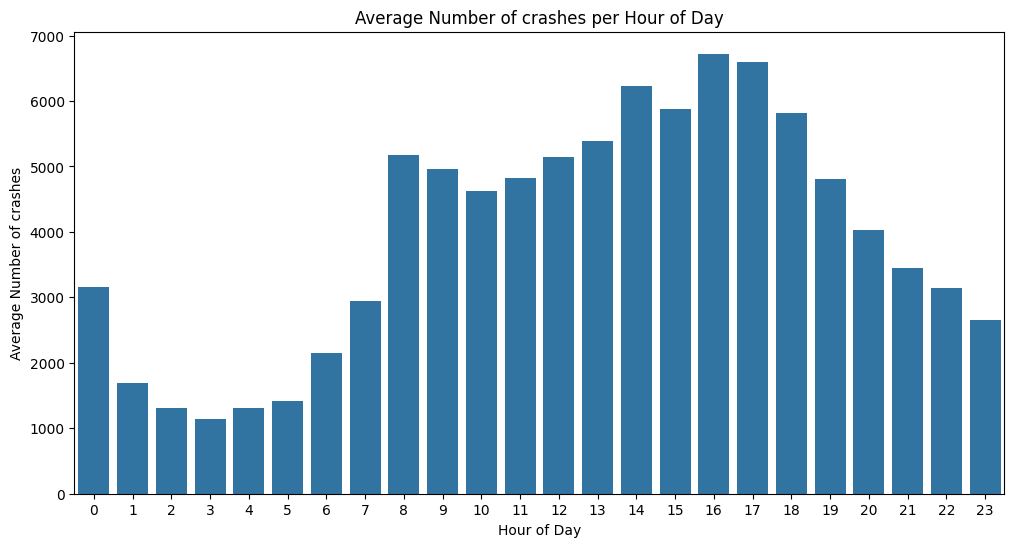

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the dataset
file_path = "/content/drive/MyDrive/Motor_Vehicle_Collisions_-_Crashes_20260611.csv"
data = pd.read_csv(file_path)

# Convert 'CRASH DATE' and 'CRASH TIME' to datetime
data['CRASH DATE'] = pd.to_datetime(data['CRASH DATE'])
data['CRASH TIME'] = pd.to_datetime(data['CRASH TIME'], format='%H:%M')

# Time of Day Analysis
data['Hour of Day'] = data['CRASH TIME'].dt.hour

# Group by 'Hour of Day' and calculate the average number of crashes per hour
average_crashes_per_hour = data.groupby('Hour of Day').size() / data['Hour of Day'].nunique()

# Plot the average number of crashes
plt.figure(figsize=(12, 6))
sns.barplot(x=average_crashes_per_hour.index, y=average_crashes_per_hour.values)
plt.title('Average Number of crashes per Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Number of crashes')
plt.xticks(range(0, 24))
plt.show()




**TO DO:** Which time of the day sees the most crashes? Why do you think so?

> * 5pm sees the most crashes since it is Rush Hour and everyone is trying to go home.



**Step 3:**
Plot a graph to determine how COVID-19 impacted the number of crashes per month, if at all.


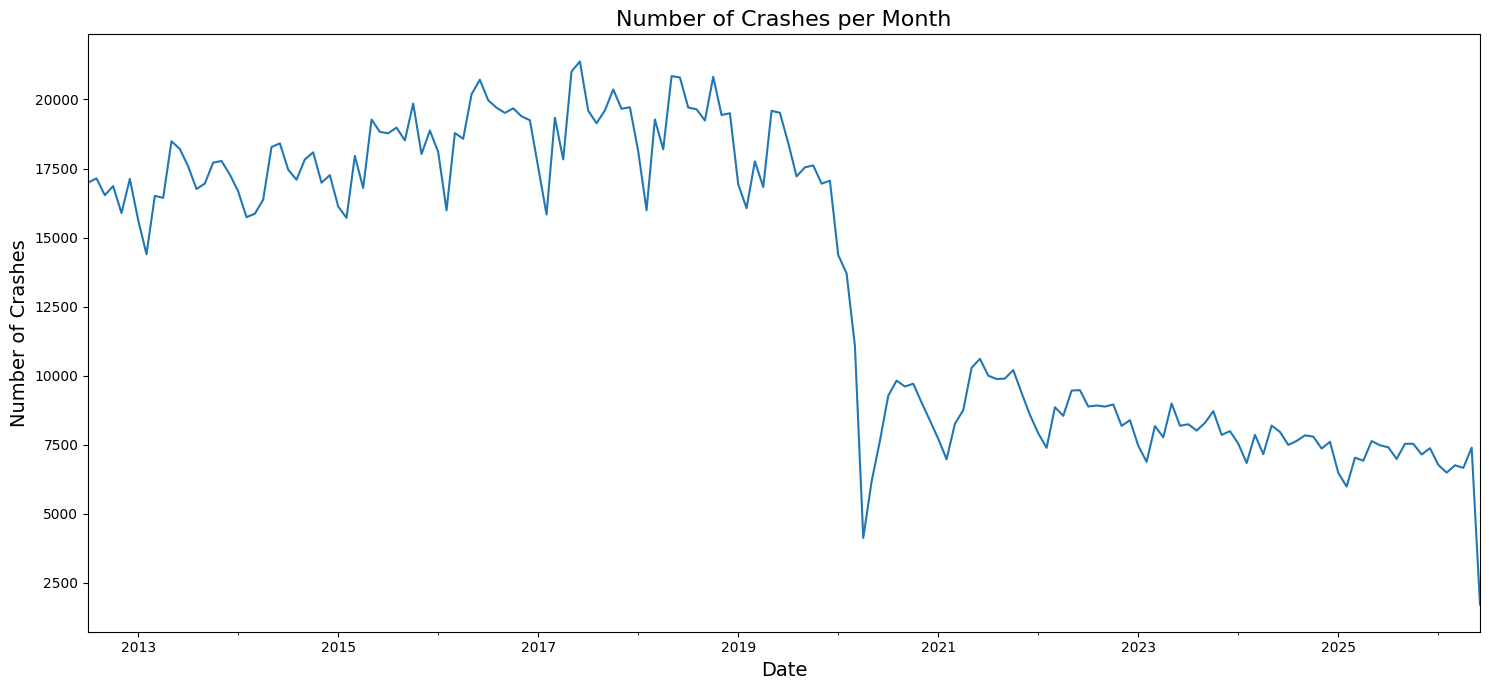

In [12]:
# Convert 'CRASH DATE' to datetime format
data['CRASH DATE'] = pd.to_datetime(data['CRASH DATE'])

# Group by month and year to get the number of crashes per month
monthly_crashes = data.groupby(data['CRASH DATE'].dt.to_period("M")).size()

# Plotting the trend over time
plt.figure(figsize=(15, 7))
monthly_crashes.plot()
plt.title('Number of Crashes per Month', fontsize=16)
plt.xlabel('Date', fontsize=14)
plt.ylabel('Number of Crashes', fontsize=14)
plt.tight_layout()
plt.show()

**TO DO:** What does your graph tell you about the impact of COVID-19 on the number of crashes per month? Why do you think this occurred?

> *  The graph shows a sudden, sharp drop in crashes in March and April 2020 This lines up with New York’s stay-at-home order, which cut traffic. Schools closed, many people worked from home, and fewer trips were made, so fewer crashes occurred.



**Step 4**: Apply time series decomposition to review trends, seasonality, and residuals. New to time series analysis? Review the [Time Series Flashcard video series](https://youtube.com/playlist?list=PLNs9ZO9jGtUAqd0CNKySksPJJaOqYPMvk&feature=shared) here to learn about trends, components, and further analysis!

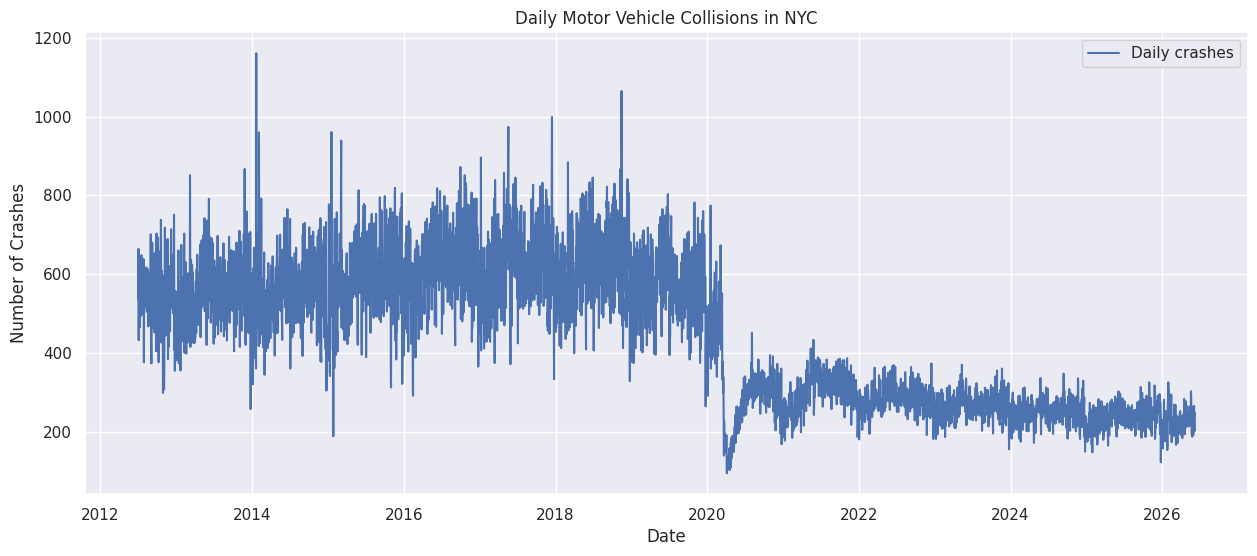

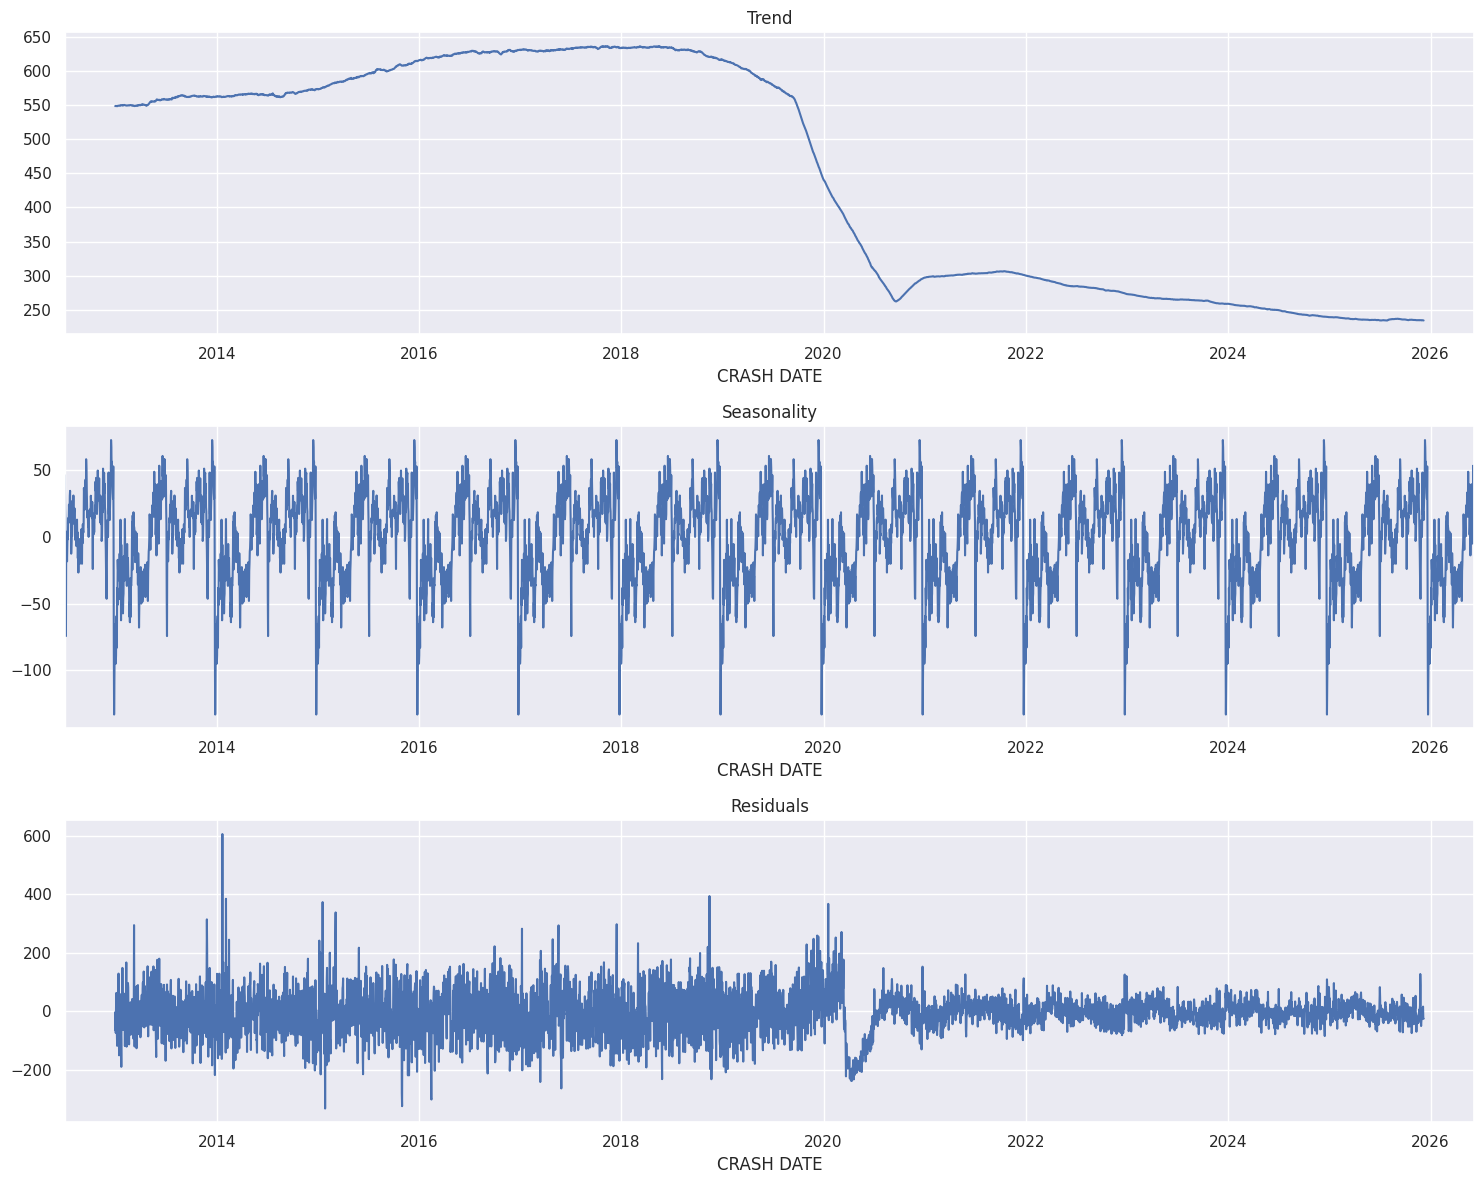

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

# Count the number of crashes per day, group by CRASH DATE
daily_crashes = data.groupby('CRASH DATE').size()

# Set plot style
sns.set(style="darkgrid")

# Plot the daily crashes time series
plt.figure(figsize=(15, 6))
plt.plot(daily_crashes, label='Daily crashes')
plt.title('Daily Motor Vehicle Collisions in NYC')
plt.xlabel('Date')
plt.ylabel('Number of Crashes')
plt.legend()
plt.show()

# Decompose the time series
decomposition = seasonal_decompose(daily_crashes, model='additive', period=365)

# Plot the decomposed components
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 12))
decomposition.trend.plot(ax=ax1)
ax1.set_title('Trend')
decomposition.seasonal.plot(ax=ax2)
ax2.set_title('Seasonality')
decomposition.resid.plot(ax=ax3)
ax3.set_title('Residuals')
plt.tight_layout()
plt.show()

The visualizations above provide valuable insights into the time series of daily motor vehicle collisions in New York City:

1. Time Series Plot: This shows the number of daily crashes over time. You might observe long-term trends, seasonal patterns, or significant outliers.

2. Decomposed Components:
  
    2.1 Trend: This graph shows the long-term trend in the data, which can indicate whether crashes are increasing, decreasing, or stable over time.

    2.2 Seasonality: This reveals any regular patterns that repeat over a specific period, such as yearly. It helps identify times of the year with higher or lower crash frequencies.

    2.3 Residuals: These are the irregular components that cannot be attributed to the trend or seasonality. They might include random or unpredictable fluctuations.

**TO DO:** Based on your *trend graph*, are we seeing an increase or a decrease in crashes between 2014 and 2022?

> *  Decrease


**TO DO:** Based on your *residual graph*, in what year(s) was there a significant unpredicted fluctuation? Why do you think so?

> *  Around the COVID period because less trips were being made.

---

##<font color='crimson'>**Milestone #4 - Geospatial Analysis**</font>
GOAL: The main goal of this milestone is to explore geospatial aspects of the dataset and get comfortable with regional analysis and geospatial visualizations.

**Step 1:** Before beginning this Milestone, we highly recommend that you review the [NSDC Geospatial Analysis Flashcard Video series](https://www.youtube.com/playlist?list=PLNs9ZO9jGtUAX_2g1-OJp8VkmVum6DqqP) if you are new to Geospatial Analysis!

Let's build a bar chart to compare and analyze the number of crashes across the five boroughs: Brooklyn (also known as Kings County), Queens, Manhattan, Bronx, and Staten Island.

/tmp/ipykernel_8959/1514107147.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=borough_count.index, y=borough_count.values, palette="viridis")


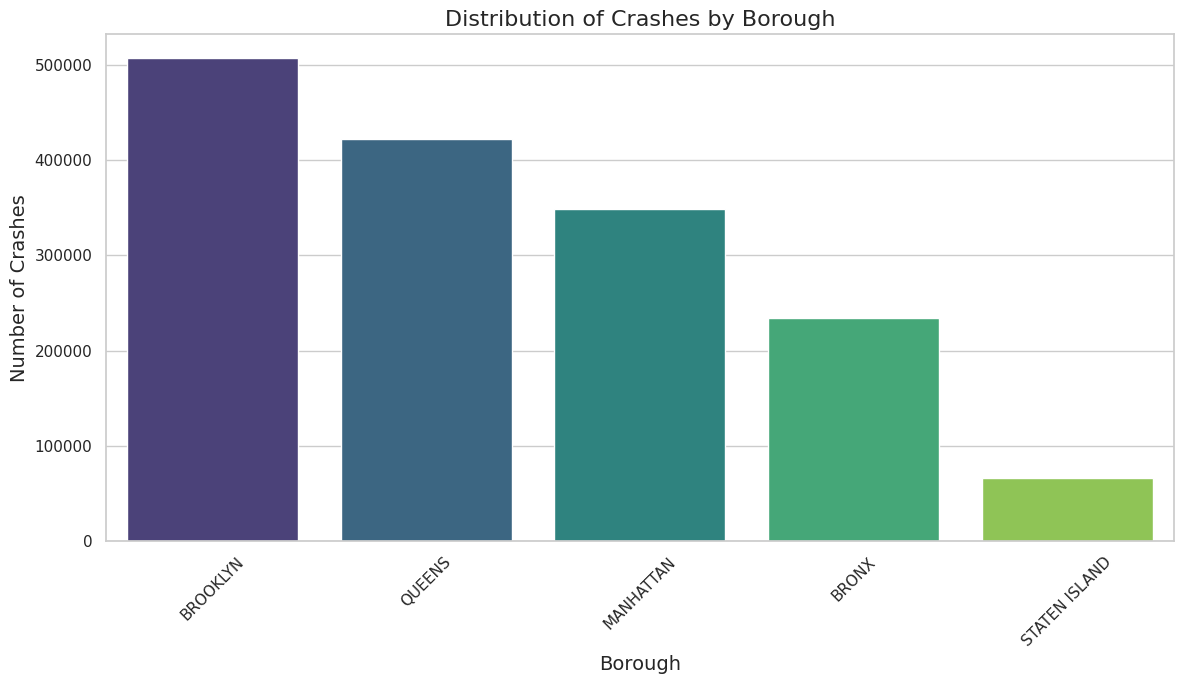

In [14]:
#TODO: Plot a bar chart to compare the number of crashes that occurred in each of the five boroughs.
# Set style
sns.set_style("whitegrid")

# Plotting the distribution of crashes by borough
plt.figure(figsize=(12, 7))
# Find the count of unique values of BOROUGHS. Hint: Use value_count function.
borough_count = data['BOROUGH'].value_counts()
sns.barplot(x=borough_count.index, y=borough_count.values, palette="viridis")
plt.title('Distribution of Crashes by Borough', fontsize=16)
plt.xlabel('Borough', fontsize=14)
plt.ylabel('Number of Crashes', fontsize=14)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**TO DO:** Which borough has the highest number of crashes? Which borough has the lowest?

> * Highest: Brooklyn
> * Lowest: Staten Island


**TO DO:** Are there any reasons that you think a certain borough has a higher or lower number of crashes? What are some factors that may be causing this?

> * Brooklyn is the most populous borough and has a dense street grid with many intersections and heavy traffic, so more crashes happen there.

**Step 2:** Heatmaps are graphical representations that use color coding to represent different values and variables. Let's leverage a heatmap to determine the most dangerous intersections in the dataset. (**Note: the below cell may take a few minutes to run**)

In [15]:
#TODO: Create a heatmap leveraging the latitude and longitude variables to determine where the most crashes are occurring
from folium.plugins import HeatMap

# Drop rows with missing latitude and longitude values
data_geo = data.dropna(subset=['LATITUDE', 'LONGITUDE'])

# Create a base map
m = folium.Map(location=[40.730610, -73.935242], zoom_start=11,
               tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
               attr='Tiles: Esri')

# Create a heatmap
heat_data = [[row['LATITUDE'], row['LONGITUDE']] for index, row in data_geo.iterrows()]
HeatMap(heat_data, radius=8, max_zoom=13).add_to(m)

m.save("Heatmap.html")


**TO DO:** On the left side of your screen, you will see an icon that represents a folder or a file. Click on that icon to find the file titled "Heatmap.html". Click on the three dots next to your file and download your heatmap! Open the file once downloaded to see your creation.

When looking at your heatmap, where do you see a concentration of crashes?


> *  Theres a concentration of crashes in upper Manhattan.



**Step 3:** Next, we will begin "Severity Mapping." We'll plot crashes on the map and code them based on severity, distinguishing between crashes that resulted in injuries and those that led to fatalities. This will give us a visual representation of where severe crashes tend to occur. </br>

You may initially want to code these incidents by using different colors, but it's important to think about your map and how accessible it is. Will a color-coded map be easy to read for everyone? Let's make a map that's inclusive for people with color blindness by also creating differently-shaped markers (squares, circles, and triangles) for crashes, injuries, and fatalities.

In [16]:
#TODO: Continue building your heatmap
# Sample a subset of the data for visualization
sample_data_severity = data_geo.sample(n=1000, random_state=42)

# Create a base map
m_severity = folium.Map(location=[40.730610, -73.935242], zoom_start=11,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles: Esri')

# Add crashes to the map with color coding and shape coding based on severity
for index, row in sample_data_severity.iterrows():
    if row['NUMBER OF PERSONS KILLED'] > 0:
        color = "#D55E00"  # Fatalities

        folium.features.RegularPolygonMarker(
          location=[row['LATITUDE'], row['LONGITUDE']],
          number_of_sides=3,
          radius=5,
          gradient = False,
          color=color,
          fill=True,
          fill_color=color
        ).add_to(m_severity)


    elif row['NUMBER OF PERSONS INJURED'] > 0:
        color = "#0072B2"  # Injuries
        folium.CircleMarker(
          location=[row['LATITUDE'], row['LONGITUDE']],
          radius=5,
          color=color,
          fill=True,
          fill_color=color
       ).add_to(m_severity)
    else:
        color = "#999999"  # No injuries or fatalities
        folium.features.RegularPolygonMarker(
          location=[row['LATITUDE'], row['LONGITUDE']],
          number_of_sides=4,
          radius=5,
          gradient = False,
          color=color,
          fill=True,
          fill_color=color
        ).add_to(m_severity)


m_severity.save("severity.html")


In [17]:
import numpy as np

inter = data_geo.dropna(subset=['ON STREET NAME', 'CROSS STREET NAME']).copy()
a = inter['ON STREET NAME'].str.upper().str.strip()
b = inter['CROSS STREET NAME'].str.upper().str.strip()
inter['INTERSECTION'] = np.where(a < b, a + ' & ' + b, b + ' & ' + a)

summary = inter.groupby('INTERSECTION').agg(
    crashes=('INTERSECTION', 'size'),
    injured=('NUMBER OF PERSONS INJURED', 'sum'),
    killed=('NUMBER OF PERSONS KILLED', 'sum'))

print(summary.sort_values('crashes', ascending=False).head(10))
print(summary.sort_values(['killed', 'injured'], ascending=False).head(10))

                                             crashes  injured  killed
INTERSECTION                                                         
FLATBUSH AVENUE EXTENSION & TILLARY STREET      1193    221.0     1.0
MAJOR DEEGAN EXPRESSWAY & WEST FORDHAM ROAD      930    397.0     0.0
BRUCKNER BOULEVARD & HUNTS POINT AVENUE          897    319.0     1.0
ATLANTIC AVENUE & PENNSYLVANIA AVENUE            865    287.0     0.0
2 AVENUE & EAST 59 STREET                        843    118.0     0.0
LINDEN BOULEVARD & PENNSYLVANIA AVENUE           786    361.0     2.0
QUEENS BOULEVARD & WOODHAVEN BOULEVARD           738    145.0     0.0
11 AVENUE & WEST 40 STREET                       712     28.0     0.0
BRUCKNER BOULEVARD & EAST 138 STREET             681    263.0     2.0
10 AVENUE & WEST 41 STREET                       639     62.0     0.0
                                       crashes  injured  killed
INTERSECTION                                                   
WEST HOUSTON STREET & WEST STREE

**TO DO:** On the left side of your screen, you will see an icon that represents a folder or a file. Follow the same steps as above to download the "Severity.html" file.

**TO DO:** Which intersection(s) seem to be the most dangerous?

> *  I would say the 2 most dangerous intersections are FLATBUSH AVENUE EXTENSION & TILLARY STREET and MAJOR DEEGAN EXPRESSWAY & WEST FORDHAM ROAD.



---
---

##<font color='crimson'>  **Milestone #5 - Self-Guided Research Question**</font>
GOAL: In this Milestone, you will be prompted to take what you’ve learned throughout this project, build your own research question, and create a visualization(s) or model(s) to support your research goals.


You may create your visualization(s) in this Colab Notebook, or in Excel, Tableau, PowerBI, etc. Choose whichever medium you are most comfortable with! Be creative!

For participants who are comfortable with advanced data science techniques, we welcome you to leverage additional datasets, if desired. We highly recommend using pre-cleaned datasets from open data sources, like Kaggle.com.

If you have any questions or get stuck, please email nsdc@nebigdatahub.org with your queries. We're here to help!

**Step 1:** Review the dataset(s) that you will be using. As you explore, [consider the research question you want to answer](https://libraries.indiana.edu/sites/default/files/Develop_a_Research_Question.pdf)! Additionally, think about [who you are telling your data's story to](https://hbr.org/2013/04/how-to-tell-a-story-with-data). Your final audience may contain a group of transportation professionals, data scientists, peers, and the general public. Think about how would you frame your analysis differently for each of these groups.

**TO DO:** List one or more research questions here that you are considering.

> * At what days and hours are crashes most likely to cause an injury or death, as a share of all crashes?
> * Do crash counts differ between under-resourced and well-resourced ZIP codes?
> * Can monthly crashes be forecast after the drop in 2020?

**Step 2:** Now, think about what type of analysis you'd like to complete. Are you interested in looking at time series forecasting? Do you have additional maps in mind that you'd like to create? Is there a certain zip code or region you'd like to dive deeper into?

If you happen to be stuck, here are some examples that you can use or can guide you in choosing your research question!

**Examples:**
- How many crashes, injuries, and/or fatalies occurred in a zip code of interest?
- Which zip code sees the highest amount of crashes and what recommendations can you offer to help that community? Is it an underserved community?
- Do more crashes occur in underrepresented communities? Support your conclusion.
- Which day of the week sees the most crashes, injuries, and/or fatalities? (Hint: use the same method we used when we were analyzing the average number of crashes at different times of the day!)
- Does the geometric features of an intersection (90 degree intersection vs skewed intersection) affect the number of crashes that occur?

Be creative and think outside the box!



**Step 3:** Now that you've decided on your transportation research question, [explore the various types of visualizations you can create to support your research](https://datavizcatalogue.com/). You may create visualizations in this Google Colab notebook, Excel, R, SQL, PowerBI, Tableau, etc. Choose a program you are comfortable with!

You may also choose to build a model or leverage a different data science technique based on your experience level.










**Step 4:** Consider the **accessibility** of the graphs, charts, maps, or models you are interested in building. Use the tools below to learn more!
* How does your visualization appear to people [who may not be able to distinguish between muted colors or see your chart at all?](https://chartability.fizz.studio/)
*[Color Contrast Checker](https://policyviz.com/2022/11/01/color-contrast-checker-in-excel/)
*[SAS Graphics Accelerator](https://support.sas.com/software/products/graphics-accelerator/index.html)
*[TwoTone Data Sonification Tool](https://twotone.io/about/)
*[Making Visual Studio Accessible](https://code.visualstudio.com/docs/editor/accessibility)

To make visualizations more inclusive for people with color blindness, you can choose a color palette that is colorblind-friendly. `Seaborn`, a Python visualization library, provides several palettes that are designed to be perceptible by those with color vision deficiencies. Seaborn's `cubehelix` palette is a good choice, as it was designed specifically with color blindness in mind.

**Step 5:** Begin your research! Give yourself plenty of time to build your visualization or model. If you have any questions along the way, please email nsdc@nebigdatahub.org or write a message in the #[tdsp-community Slack Channel](https://join.slack.com/t/nsdcorps/shared_invite/zt-1h64t1e2p-La0AgU_HhymWUEGFQEcb3w).

**TO DO:** List the research question(s) you've chosen and why! Maybe you chose this question because it can help a community of interest or because it is similar to research you've completed in a class setting. Share your thoughts below.

> *  I chose to study when crashes are most likely to be severe, not just when they are most common. My earlier chart of crashes by hour mostly reflects how many vehicles are on the road. The share of crashes that cause an injury or death says more about severity. This could help transportation agencies focus enforcement, lighting and signal timing on the hours when crashes do the most harm. It also builds on the hourly and monthly time patterns I analyzed earlier in this project.

**TO DO:** Build a visualization, model, or use other statistical methods to gain insights into your data and to support your research question.

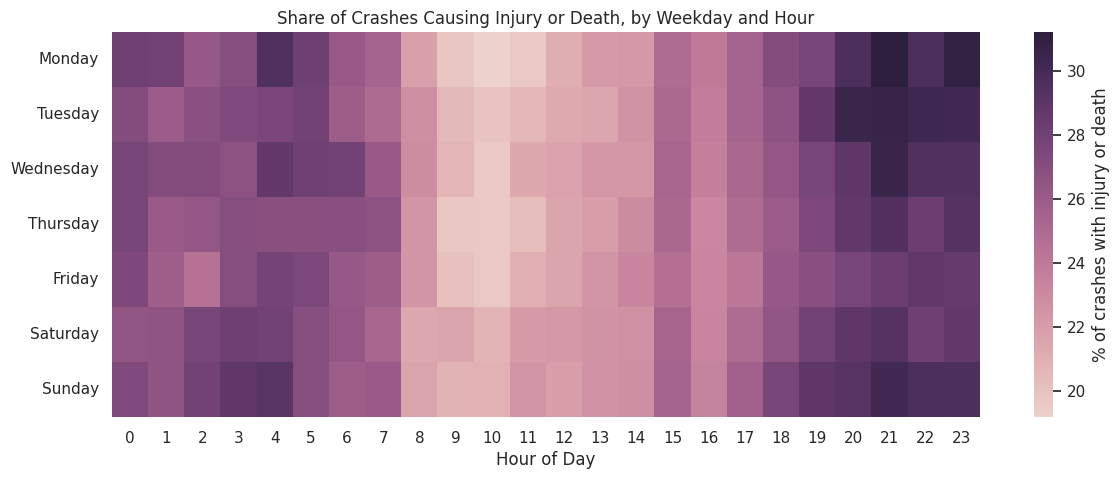

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

d = data.copy()
d['weekday'] = pd.to_datetime(d['CRASH DATE']).dt.day_name()
d['severe'] = (d['NUMBER OF PERSONS INJURED'].fillna(0) + d['NUMBER OF PERSONS KILLED'].fillna(0)) > 0

order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
share = (d.groupby(['weekday', 'Hour of Day'])['severe'].mean()
           .unstack('Hour of Day').reindex(order)) * 100

plt.figure(figsize=(14, 5))
sns.heatmap(share, cmap=sns.cubehelix_palette(as_cmap=True),
            cbar_kws={'label': '% of crashes with injury or death'})
plt.title('Share of Crashes Causing Injury or Death, by Weekday and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('')
plt.show()

In [19]:
s = share.stack().sort_values()
print(s.head(5))
print(s.tail(5))
print(d['severe'].mean() * 100)

weekday    Hour of Day
Monday     10             19.185177
Wednesday  10             19.669278
Friday     10             19.681679
Thursday   10             19.696455
Monday     11             19.700520
dtype: float64
weekday    Hour of Day
Tuesday    20             30.514678
Wednesday  21             30.583078
Tuesday    21             30.600441
Monday     23             30.893265
           21             31.206930
dtype: float64
24.725740963348226


In [20]:
print(len(data))
print(data['CRASH DATE'].min(), data['CRASH DATE'].max())
print(data['LATITUDE'].isnull().mean() * 100)

2268567
2012-07-01 00:00:00 2026-06-07 00:00:00
10.614718454425194


---

##<font color='crimson'>**Milestone #6 - Virtual Poster Board Creation: Data Storytelling**</font>

GOAL: The main goal of this milestone is to create a one page, virtual poster board to portray your research findings and recommendations! Your poster may be shared with the Department of Transportation and Federal Highway Authority.

Within your poster, summarize your research question, your reasoning for selecting your data visualization or model choices, and key insights from your data analysis. You may also wish to include your outstanding research questions that could not be answered by the dataset and why.

**Be sure to answer the following on your virtual poster board:** Based on your research insights, what recommendations would you share with the Department of Transportation and Federal Highway Authority to make roads safer for vulnerable road users? Why?

**Additionally, be sure to cite all relevant sources that you referred to throughout this project on your poster board (MLA or APA citation preferred). List acknowlegdments if you received any support from mentors, professors, professionals, etc. throughout your journey.**




 Please use the following resources to get started!


*   [Virtual Poster Board Template](https://nebigdatahub.org/wp-content/uploads/2024/01/Copy-of-dsi-poster.ppt-48-×-36-in.pdf) - Your one-page, virtual poster may be created in PowerPoint, Google Slides, Canva, etc. Choose what you are most comfortable with!
* [ Data Storytelling: How to Effectively Tell a Story with Data](https://online.hbs.edu/blog/post/data-storytelling)

* [  Consider how your visualization(s) might appear to people with varying abilities ](https://chartability.fizz.studio/)
*  [Understand your audience for an optimal presentation](https://hbr.org/2013/04/how-to-tell-a-story-with-data)


Once completed, please use the [following TDSP Submission Form](https://docs.google.com/forms/d/e/1FAIpQLSeX1OSHj58EQs4ypFEPB_SH3OpWZeo67yU0WWOPVSqYtDrpWg/viewform) to share your Google Colab Notebook and your one-page, virtual project poster with the NSDC HQ Team.


---
---

## 🚗<font color='crimson'> **Thank you for completing the project!**</font> 🚗

We are one step closer to making roads safer for all. [Please submit all materials to the NSDC HQ team](https://docs.google.com/forms/d/e/1FAIpQLSeX1OSHj58EQs4ypFEPB_SH3OpWZeo67yU0WWOPVSqYtDrpWg/viewform) in order to receive a certificate of completion. Do reach out to us if you have any questions or concerns. We are here to help you learn and grow.
